# For Reference

### AT - Ambient Temperature
### V - Exhaust Vacuum
### AP - Ambient pressure
### RH - Relative humidity
### PE - Electric  power Output

# **Importing Libraries and Loading Data**

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv(r'../data/dataset.csv')

## Checking the structure of the dataset

In [9]:
# Basic information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (9568, 5)

Column names:
['AT', 'V', 'AP', 'RH', 'PE']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB

First 5 rows:


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## Inspecting the data for missing values and Duplicates

In [10]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Total missing values: 0

Number of duplicate rows: 41


# Statistical Analysis of the Dataset

Mean:
AT      19.651231
V       54.305804
AP    1013.259078
RH      73.308978
PE     454.365009
dtype: float64
Median:
AT      20.345
V       52.080
AP    1012.940
RH      74.975
PE     451.550
dtype: float64
Standard Deviation:
AT     7.452473
V     12.707893
AP     5.938784
RH    14.600269
PE    17.066995
dtype: float64
Covariance:
            AT           V         AP          RH          PE
AT   55.539357   79.941324 -22.463437  -59.032171 -120.593715
V    79.941324  161.490544 -31.206771  -57.922808 -188.642778
AP  -22.463437  -31.206771  35.269152    8.633874   52.546510
RH  -59.032171  -57.922808   8.633874  213.167848   97.129952
PE -120.593715 -188.642778  52.546510   97.129952  291.282318
Correlation:
          AT         V        AP        RH        PE
AT  1.000000  0.844107 -0.507549 -0.542535 -0.948128
V   0.844107  1.000000 -0.413502 -0.312187 -0.869780
AP -0.507549 -0.413502  1.000000  0.099574  0.518429
RH -0.542535 -0.312187  0.099574  1.000000  0.389794
PE -0.948128 -

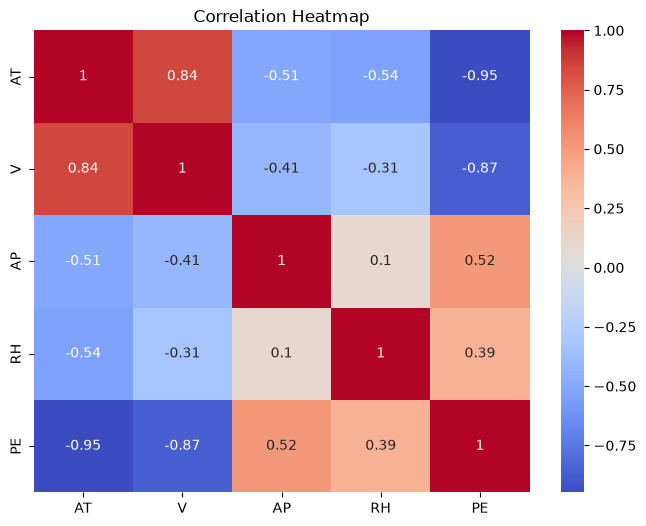

In [11]:
# Mean
print("Mean:")
print(df.mean())

# Median
print("Median:")
print(df.median())

# Standard deviation
print("Standard Deviation:")
print(df.std())

# Covariance
print("Covariance:")
print(df.cov())

# Correlation
print("Correlation:")
print(df.corr())

# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Creating Project Directories

In [12]:
import os
folders = [
    "../plots/EDA",
    "../plots/Feature_Selection",
    "../plots/Model_Evaluation"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


# Data Preparation and Train-Test Split

In [13]:
# Duplicate values
print("Duplicates:", df.duplicated().sum())

# Remove duplicates if any
#df = df.drop_duplicates()
print(f"Dataset size after removing duplicates: {df.shape}")

X = df[['AT', 'V', 'AP', 'RH']]
y = df['PE']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training percentage:",
      len(X_train) / len(X) * 100)

print("Testing percentage:",
      len(X_test) / len(X) * 100)

Duplicates: 41
Dataset size after removing duplicates: (9568, 5)
Shape of X: (9568, 4)
Shape of y: (9568,)
Training features: (7654, 4)
Testing features: (1914, 4)
Training target: (7654,)
Testing target: (1914,)
Total samples: 9568
Training samples: 7654
Testing samples: 1914
Training percentage: 79.9958193979933
Testing percentage: 20.004180602006688
